In [1]:
from datetime import date

today = date.today()
print(f'Last full compilation {today}')

Last full compilation 2023-06-01


Lecture des données réalisée en 0.68219s
-  -  -  -  -  -  -  -  -  -  


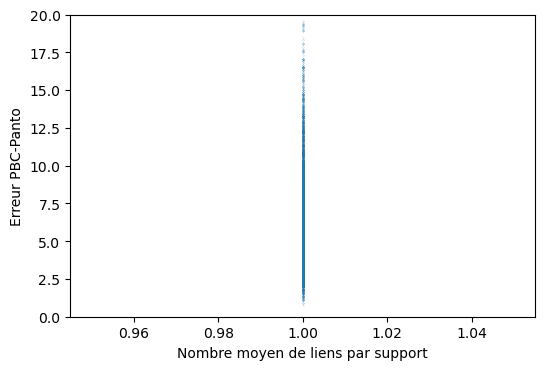

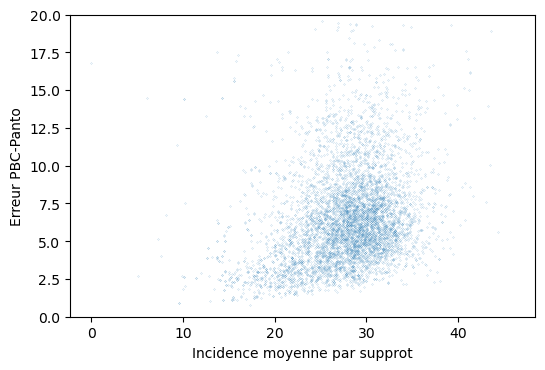

<Figure size 600x400 with 0 Axes>

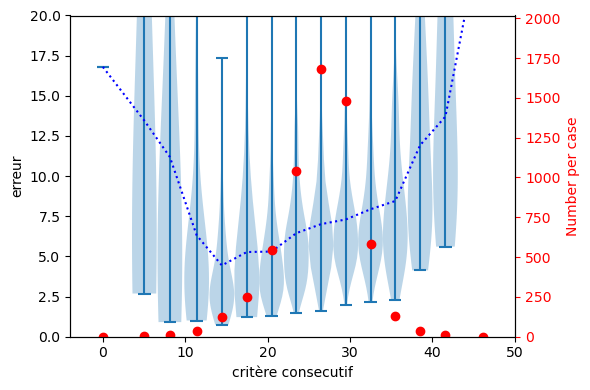

In [2]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
from math import *
import os

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100

campagnes = ['campagne_carre']
data = get_bulk_data(read_data_from_campaigns(campagnes))


supports_data = np.zeros((len(data), 3))
supports_data[:] = np.nan
counter = 0

for test_id, test in data.items():
    with open(f'../KUBC_support_analysis/bis/{test_id}.txt') as f:
        for _ in range(43):
            next(f)
        supports_list = []
        for l in range(40):
            line = f.readline().split(' ')
            s=0
            counter_i=1
            for it in line:
                try:
                    s=s+float(it)
                    counter_i+=1
                except:
                    pass
            supports_list.append(abs(s))
    supports_data[counter, 0] = len(supports_list)/40  # Nb moyen de lien
    supports_data[counter, 1] = sum(supports_list)/(40-test.get_number_ms()) #incidence moyenne
    supports_data[counter, 2] = test.get_error((0,3))
    counter += 1

print('-  '*10)
plt.scatter(supports_data[:,0],supports_data[:,2],s=0.01)
plt.xlabel('Nombre moyen de liens par support')
plt.ylabel('Erreur PBC-Panto')
plt.ylim((0,20))

plt.figure()
plt.scatter(supports_data[:,1],supports_data[:,2],s=0.01)
plt.xlabel('Incidence moyenne par supprot')
plt.ylabel('Erreur PBC-Panto')
plt.ylim((0,20))

plt.figure()
plot_box2(supports_data[:,1],supports_data[:,2], step=3, ylabel=f'Résultante moyenne des angles d\'incidence des cylindres', width=3,ylim=(0,20))


Lecture des données réalisée en 0.85118s
- - - - - - - - - - 


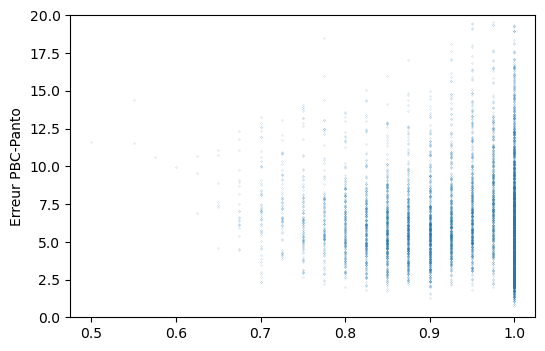

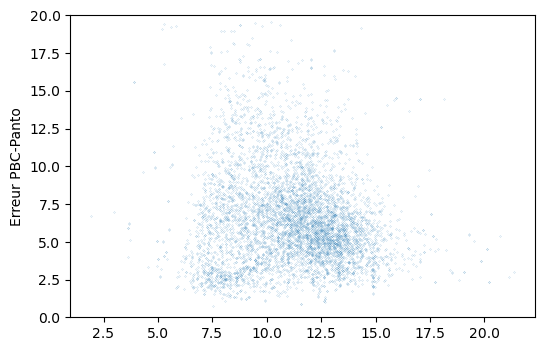

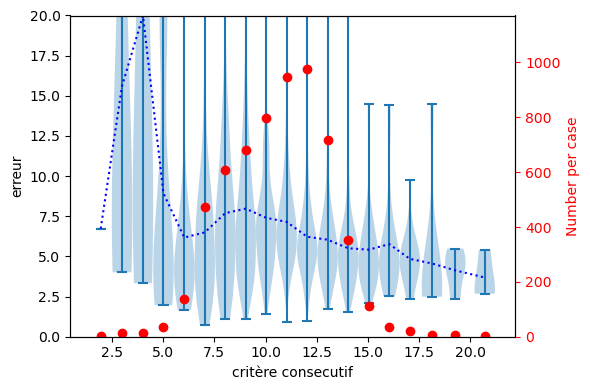

In [3]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
from math import *
import os

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100

campagnes = ['campagne_carre']
data = get_bulk_data(read_data_from_campaigns(campagnes))
# data = get_tests_by_test_id(data, index=1, target='7')

supports_data = np.zeros((len(data), 3))
supports_data[:] = np.nan
counter = 0

for test_id, test in data.items():
    with open(f'../KUBC_support_analysis/bis/{test_id}.txt') as f:
        for _ in range(84):
            next(f)
        supports_list = []
        for l in range(40):
            line = f.readline().split(' ')
            s=0
            l=[]
            counter_i=1
            for it in line:
                try:
                    s+=1/max([float(it)**3,1])
                    l.append(float(it))
                    counter_i+=1
                except:
                    pass
            
            try:
                supports_list.append(min(l))
            except:
                pass
    supports_data[counter, 0] = len(supports_list)/40  # Nb moyen de lien
    supports_data[counter, 1] = sum(supports_list)/(40) #incidence moyenne
    supports_data[counter, 2] = test.get_error((0,3))
    counter += 1

print('- '*10)
plt.scatter(supports_data[:,0],supports_data[:,2],s=0.01)
plt.ylabel('Erreur PBC-Panto')
plt.ylim((0,20))

plt.figure()
plt.scatter(supports_data[:,1],supports_data[:,2],s=0.01)

plt.ylabel('Erreur PBC-Panto')
plt.ylim((0,20))
# plt.xlim((0,0.1))

plot_box2(supports_data[:,1],supports_data[:,2], step=1.0, ylabel=f'critère consecutif', width=1.0,ylim=(0.0,20))